In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

SEED = 42
np.random.seed(SEED)

os.makedirs("resultats", exist_ok=True)

In [2]:
iris = load_iris()
X, y = iris.data, iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["classe"] = y

print("Dimensions :", X.shape)
print("Classes :", iris.target_names)
df.head()

Dimensions : (150, 4)
Classes : ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),classe
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print(df.describe())
print("\nNombre d'échantillons par classe :")
print(df["classe"].value_counts())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      classe  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  

Nombre d'échantillons par classe :
classe
0    50
1    50
2    50
Name:

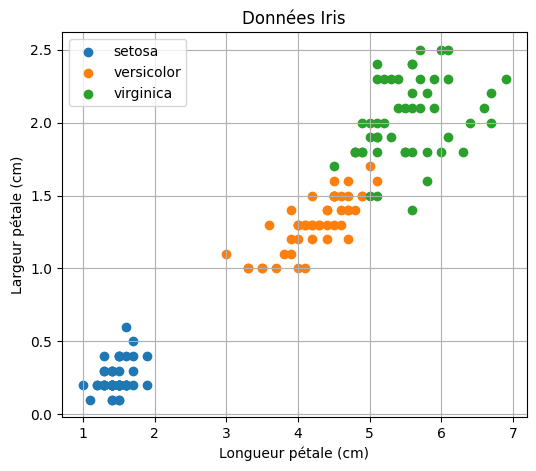

In [4]:
plt.figure(figsize=(6, 5))
for c in range(3):
    plt.scatter(X[y == c, 2], X[y == c, 3], label=iris.target_names[c])
plt.xlabel("Longueur pétale (cm)")
plt.ylabel("Largeur pétale (cm)")
plt.title("Données Iris")
plt.legend()
plt.grid(True)
plt.savefig("resultats/fig1_donnees_iris.png", dpi=150)
plt.show()

Séparation train/test et normalisation

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

separation train/test

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Taille train :", X_train.shape)
print("Taille test  :", X_test.shape)
print("\nRépartition des classes (train) :", np.bincount(y_train))
print("Répartition des classes (test)  :", np.bincount(y_test))

Taille train : (120, 4)
Taille test  : (30, 4)

Répartition des classes (train) : [40 40 40]
Répartition des classes (test)  : [10 10 10]


normalisation

In [7]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   # apprend moyenne et écart-type sur le train
X_test = scaler.transform(X_test)         # applique les mêmes valeurs au test

verification

In [8]:
print("Moyenne des colonnes (train) :", X_train.mean(axis=0).round(3))
print("Écart-type des colonnes (train) :", X_train.std(axis=0).round(3))
print("\nMoyenne des colonnes (test) :", X_test.mean(axis=0).round(3))
print("Écart-type des colonnes (test) :", X_test.std(axis=0).round(3))

Moyenne des colonnes (train) : [-0. -0.  0.  0.]
Écart-type des colonnes (train) : [1. 1. 1. 1.]

Moyenne des colonnes (test) : [ 0.01   0.101 -0.034 -0.037]
Écart-type des colonnes (test) : [0.925 0.849 0.995 1.001]


La fonction objectif (SVM + validation croisée
1.fonction objectif

In [9]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [12]:
# Bornes en log10 : [min, max] pour chaque dimension (floats !)
bounds = np.array([[-2.0, 3.0],    # log10(C)     -> C     dans [0.01, 1000]
                   [-4.0, 1.0]])   # log10(gamma) -> gamma dans [0.0001, 10]

print("Espace de recherche :")
print(f"  C     dans [{10**bounds[0,0]}, {10**bounds[0,1]}]")
print(f"  gamma dans [{10**bounds[1,0]}, {10**bounds[1,1]}]")

Espace de recherche :
  C     dans [0.01, 1000.0]
  gamma dans [0.0001, 10.0]


validation croise

In [13]:
# Mêmes découpages à chaque évaluation : la fonction objectif devient déterministe
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

fonction objectif

In [14]:
def objective(position):
    """
    position : [log10(C), log10(gamma)]
    retourne : erreur de classification en validation croisée (à minimiser)
    """
    C = 10 ** position[0]
    gamma = 10 ** position[1]
    model = SVC(C=C, gamma=gamma, kernel="rbf")
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    return 1 - scores.mean()

test et validation

In [15]:
# Test 1 : valeurs par défaut de sklearn (C=1, gamma=0.1 environ)
print("Erreur C=1, gamma=0.1   :", round(objective([0, -1]), 4))

# Test 2 : un mauvais choix (C très petit, gamma très grand)
print("Erreur C=0.01, gamma=10 :", round(objective([-2, 1]), 4))

# Test 3 : un choix raisonnable
print("Erreur C=10, gamma=0.01 :", round(objective([1, -2]), 4))

# Vérification du déterminisme : même position = même valeur
print("\nDéterminisme :", objective([0, -1]) == objective([0, -1]))

Erreur C=1, gamma=0.1   : 0.025
Erreur C=0.01, gamma=10 : 0.275
Erreur C=10, gamma=0.01 : 0.025

Déterminisme : True


visualisation du paysage d’erreur

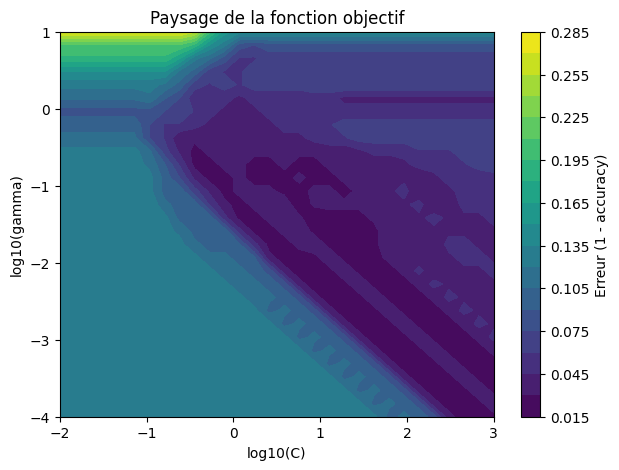

In [16]:
# Grille 30 x 30 pour visualiser la fonction objectif
log_C = np.linspace(bounds[0, 0], bounds[0, 1], 30)
log_gamma = np.linspace(bounds[1, 0], bounds[1, 1], 30)

Z = np.zeros((30, 30))
for i, g in enumerate(log_gamma):
    for j, c in enumerate(log_C):
        Z[i, j] = objective([c, g])

plt.figure(figsize=(7, 5))
plt.contourf(log_C, log_gamma, Z, levels=20, cmap="viridis")
plt.colorbar(label="Erreur (1 - accuracy)")
plt.xlabel("log10(C)")
plt.ylabel("log10(gamma)")
plt.title("Paysage de la fonction objectif")
plt.savefig("resultats/fig2_paysage_objectif.png", dpi=150)
plt.show()

Implémentation du PSO from scratch:
Écrire l’algorithme PSO sous forme d’une fonction pso(...) réutilisable. Elle explore l’espace (log10(C), log10(gamma)) et retourne la meilleure position trouvée, avec l’historique de convergence.

Implementaion de PSO

In [17]:
def pso(objective, bounds, n_particles=20, n_iter=30,
        w=0.7, c1=1.5, c2=1.5, seed=SEED, verbose=True):
    """
    PSO pour minimiser une fonction objectif.

    Retourne : gbest (meilleure position), gbest_val (meilleure valeur),
               history (meilleure valeur à chaque itération),
               positions_history (positions de l'essaim à chaque itération)
    """
    rng = np.random.default_rng(seed)
    dim = len(bounds)
    low, high = bounds[:, 0], bounds[:, 1]

    # 1) Initialisation : positions aléatoires, vitesses nulles
    pos = rng.uniform(low, high, (n_particles, dim))
    vel = np.zeros((n_particles, dim))

    # 2) Meilleures positions personnelles
    pbest = pos.copy()
    pbest_val = np.array([objective(p) for p in pos])

    # 3) Meilleure position globale
    gbest = pbest[np.argmin(pbest_val)].copy()
    gbest_val = pbest_val.min()

    history = [gbest_val]
    positions_history = [pos.copy()]

    # 4) Boucle principale
    for it in range(n_iter):
        for i in range(n_particles):
            r1 = rng.random(dim)
            r2 = rng.random(dim)

            # Mise à jour de la vitesse
            vel[i] = (w * vel[i]
                      + c1 * r1 * (pbest[i] - pos[i])
                      + c2 * r2 * (gbest - pos[i]))

            # Mise à jour de la position (on reste dans les bornes)
            pos[i] = np.clip(pos[i] + vel[i], low, high)

            # Évaluation
            val = objective(pos[i])

            # Mise à jour de pbest et gbest
            if val < pbest_val[i]:
                pbest[i] = pos[i].copy()
                pbest_val[i] = val
                if val < gbest_val:
                    gbest = pos[i].copy()
                    gbest_val = val

        history.append(gbest_val)
        positions_history.append(pos.copy())

        if verbose:
            print(f"Itération {it+1:2d}/{n_iter} | meilleure erreur : {gbest_val:.4f}")

    return gbest, gbest_val, history, positions_history

test rapide sur une fonction simple

Avant de lancer le PSO sur le SVM (lent), on vérifie qu’il fonctionne sur une fonction dont on connaît le minimum.

In [18]:
# Fonction sphère : minimum = 0 en (0, 0)
def sphere(x):
    return x[0]**2 + x[1]**2

test_bounds = np.array([[-5.0, 5.0],
                        [-5.0, 5.0]])

best, best_val, hist, _ = pso(sphere, test_bounds, n_particles=15, n_iter=30, verbose=False)

print("Meilleure position trouvée :", best.round(5))
print("Meilleure valeur trouvée   :", best_val)
print("Valeur attendue            : 0")

Meilleure position trouvée : [0.00453 0.00013]
Meilleure valeur trouvée   : 2.0499042959092282e-05
Valeur attendue            : 0


Lancement du PSO sur le SVM :Lancer le PSO avec la fonction objectif du SVM, récupérer les meilleurs hyperparamètres C et gamma, puis évaluer le modèle final sur le test

In [19]:
import time

start = time.time()
best_pos, best_err, history, positions_history = pso(
    objective, bounds, n_particles=20, n_iter=30,
    w=0.7, c1=1.5, c2=1.5, seed=SEED, verbose=True
)
pso_time = time.time() - start

print(f"\nTemps d'exécution : {pso_time:.1f} s")

Itération  1/30 | meilleure erreur : 0.0167
Itération  2/30 | meilleure erreur : 0.0167
Itération  3/30 | meilleure erreur : 0.0167
Itération  4/30 | meilleure erreur : 0.0167
Itération  5/30 | meilleure erreur : 0.0167
Itération  6/30 | meilleure erreur : 0.0167
Itération  7/30 | meilleure erreur : 0.0167
Itération  8/30 | meilleure erreur : 0.0167
Itération  9/30 | meilleure erreur : 0.0167
Itération 10/30 | meilleure erreur : 0.0167
Itération 11/30 | meilleure erreur : 0.0167
Itération 12/30 | meilleure erreur : 0.0167
Itération 13/30 | meilleure erreur : 0.0167
Itération 14/30 | meilleure erreur : 0.0167
Itération 15/30 | meilleure erreur : 0.0167
Itération 16/30 | meilleure erreur : 0.0167
Itération 17/30 | meilleure erreur : 0.0167
Itération 18/30 | meilleure erreur : 0.0167
Itération 19/30 | meilleure erreur : 0.0167
Itération 20/30 | meilleure erreur : 0.0167
Itération 21/30 | meilleure erreur : 0.0167
Itération 22/30 | meilleure erreur : 0.0167
Itération 23/30 | meilleure erre

meilleurs hyperparamètres

In [20]:
best_C = 10 ** best_pos[0]
best_gamma = 10 ** best_pos[1]

print("Meilleure position (log10) :", best_pos.round(4))
print(f"Meilleur C     : {best_C:.4f}")
print(f"Meilleur gamma : {best_gamma:.4f}")
print(f"Erreur CV      : {best_err:.4f}")
print(f"Accuracy CV    : {1 - best_err:.4f}")

Meilleure position (log10) : [ 1.8476 -2.471 ]
Meilleur C     : 70.4079
Meilleur gamma : 0.0034
Erreur CV      : 0.0167
Accuracy CV    : 0.9833


evaluation final sur le test

In [21]:
from sklearn.metrics import accuracy_score

# Modèle optimisé par PSO, entraîné sur tout le train
model_pso = SVC(C=best_C, gamma=best_gamma, kernel="rbf")
model_pso.fit(X_train, y_train)
acc_pso = accuracy_score(y_test, model_pso.predict(X_test))

# Baseline : SVM avec paramètres par défaut de sklearn
model_default = SVC()
model_default.fit(X_train, y_train)
acc_default = accuracy_score(y_test, model_default.predict(X_test))

print(f"Accuracy test (PSO)     : {acc_pso:.4f}")
print(f"Accuracy test (défaut)  : {acc_default:.4f}")

Accuracy test (PSO)     : 0.9667
Accuracy test (défaut)  : 0.9667


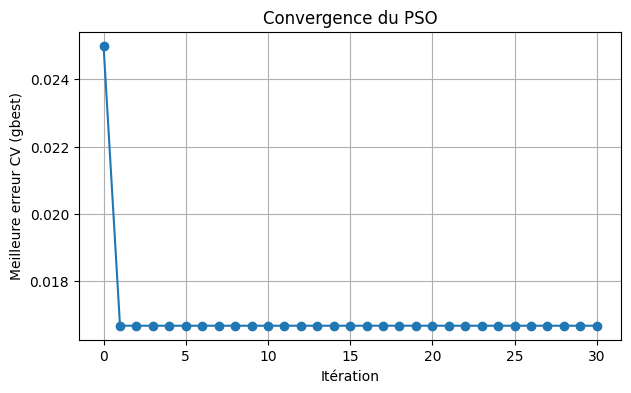

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(history, marker="o")
plt.xlabel("Itération")
plt.ylabel("Meilleure erreur CV (gbest)")
plt.title("Convergence du PSO")
plt.grid(True)
plt.savefig("resultats/fig3_convergence_pso.png", dpi=150)
plt.show()

visualisation de l’essaim

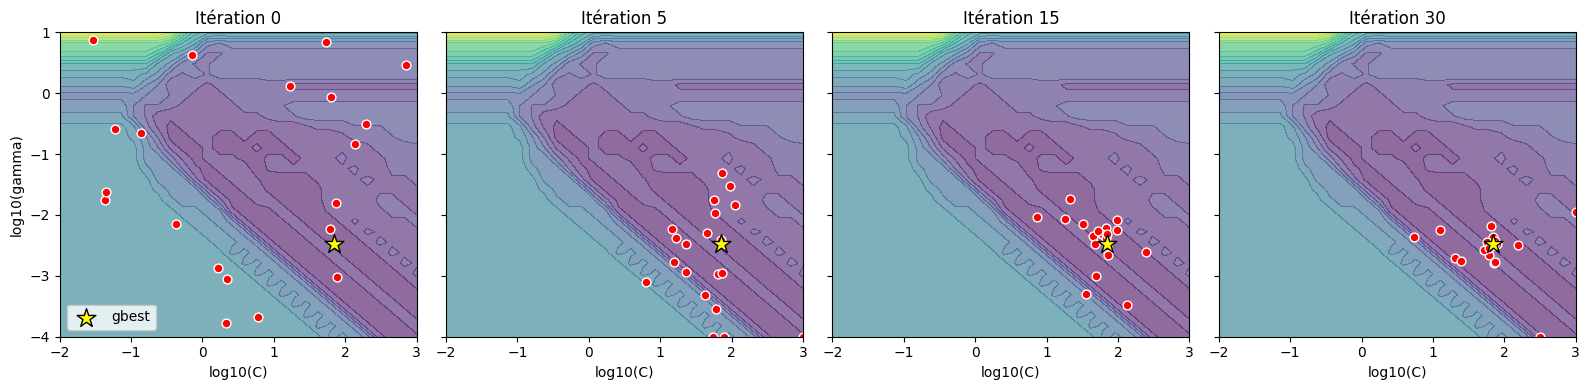

In [23]:
# Itérations à afficher
iters = [0, 5, 15, 30]

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)

for ax, it in zip(axes, iters):
    ax.contourf(log_C, log_gamma, Z, levels=20, cmap="viridis", alpha=0.6)
    p = positions_history[it]
    ax.scatter(p[:, 0], p[:, 1], c="red", edgecolor="white", s=40)
    ax.scatter(best_pos[0], best_pos[1], marker="*", c="yellow",
               edgecolor="black", s=200, label="gbest")
    ax.set_title(f"Itération {it}")
    ax.set_xlabel("log10(C)")

axes[0].set_ylabel("log10(gamma)")
axes[0].legend()
plt.tight_layout()
plt.savefig("resultats/fig4_essaim.png", dpi=150)
plt.show()

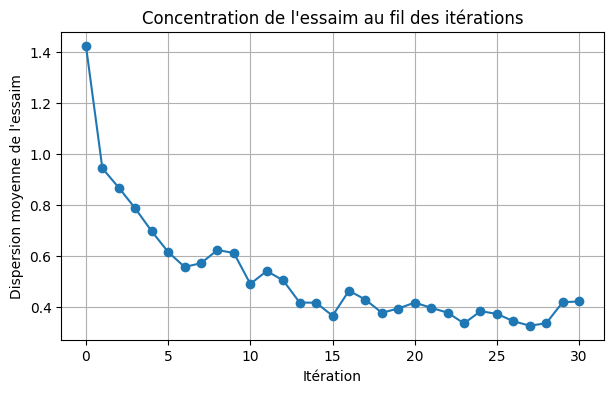

Dispersion initiale : 1.4262
Dispersion finale   : 0.4212


In [42]:
# Écart-type des positions : mesure de la concentration de l'essaim
dispersion = [np.std(p, axis=0).mean() for p in positions_history]

plt.figure(figsize=(7, 4))
plt.plot(dispersion, marker="o")
plt.xlabel("Itération")
plt.ylabel("Dispersion moyenne de l'essaim")
plt.title("Concentration de l'essaim au fil des itérations")
plt.grid(True)
plt.savefig("resultats/fig5_dispersion.png", dpi=150)
plt.show()

print("Dispersion initiale :", round(dispersion[0], 4))
print("Dispersion finale   :", round(dispersion[-1], 4))

Comparaison PSO vs GridSearchCV vs valeurs par défaut
Objectif:
Comparer trois approches sur trois critères : l’erreur CV, l’accuracy test et le temps de calcul.

GridSearchCV

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": np.logspace(bounds[0, 0], bounds[0, 1], 25),
    "gamma": np.logspace(bounds[1, 0], bounds[1, 1], 25),
}

start = time.time()
grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=cv, scoring="accuracy")
grid.fit(X_train, y_train)
grid_time = time.time() - start

grid_err = 1 - grid.best_score_
acc_grid = accuracy_score(y_test, grid.best_estimator_.predict(X_test))

print("Meilleurs paramètres (Grid) :", grid.best_params_)
print(f"Erreur CV : {grid_err:.4f}")
print(f"Accuracy test : {acc_grid:.4f}")
print(f"Temps : {grid_time:.1f} s")

Meilleurs paramètres (Grid) : {'C': np.float64(0.464158883361278), 'gamma': np.float64(0.1333521432163324)}
Erreur CV : 0.0250
Accuracy test : 0.9000
Temps : 29.7 s


erreur CV du modèle par défaut

In [26]:
scores_default = cross_val_score(SVC(), X_train, y_train, cv=cv, scoring="accuracy")
default_err = 1 - scores_default.mean()
print(f"Erreur CV (défaut) : {default_err:.4f}")

Erreur CV (défaut) : 0.0333


In [27]:
resultats = pd.DataFrame({
    "Méthode": ["Défaut", "GridSearchCV", "PSO"],
    "C": [1.0, grid.best_params_["C"], best_C],
    "gamma": ["scale", grid.best_params_["gamma"], best_gamma],
    "Erreur CV": [default_err, grid_err, best_err],
    "Accuracy test": [acc_default, acc_grid, acc_pso],
    "Évaluations": [1, 625, 20 * 31],
    "Temps (s)": [None, round(grid_time, 1), round(pso_time, 1)],
})

resultats["Erreur CV"] = resultats["Erreur CV"].round(4)
resultats["Accuracy test"] = resultats["Accuracy test"].round(4)

print(resultats.to_string(index=False))
resultats.to_csv("resultats/tableau_comparaison.csv", index=False)

     Méthode         C     gamma  Erreur CV  Accuracy test  Évaluations  Temps (s)
      Défaut  1.000000     scale     0.0333         0.9667            1        NaN
GridSearchCV  0.464159  0.133352     0.0250         0.9000          625       29.7
         PSO 70.407902   0.00338     0.0167         0.9667          620       28.7


graphique comparatif

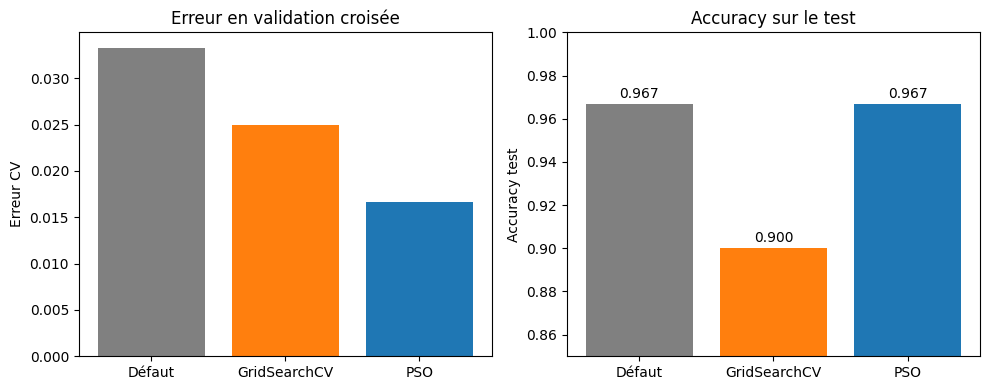

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
noms = resultats["Méthode"]
couleurs_m = ["gray", "tab:orange", "tab:blue"]

axes[0].bar(noms, resultats["Erreur CV"], color=couleurs_m)
axes[0].set_ylabel("Erreur CV")
axes[0].set_title("Erreur en validation croisée")

axes[1].bar(noms, resultats["Accuracy test"], color=couleurs_m)
axes[1].set_ylabel("Accuracy test")
axes[1].set_ylim(0.85, 1.0)
axes[1].set_title("Accuracy sur le test")
for i, v in enumerate(resultats["Accuracy test"]):
    axes[1].text(i, v + 0.003, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.savefig("resultats/fig6_comparaison.png", dpi=150)
plt.show()

Répétitions du PSO avec plusieurs seeds

In [29]:
n_runs = 10
seeds = [SEED + i for i in range(n_runs)]   # 42, 43, ..., 51 (le premier = étape 5)

runs = []
for s in seeds:
    t0 = time.time()
    g, g_val, hist, _ = pso(objective, bounds, n_particles=20, n_iter=30,
                            w=0.7, c1=1.5, c2=1.5, seed=s, verbose=False)
    t = time.time() - t0

    C_s, gamma_s = 10 ** g[0], 10 ** g[1]
    model = SVC(C=C_s, gamma=gamma_s, kernel="rbf").fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))

    runs.append({"seed": s, "C": C_s, "gamma": gamma_s,
                 "Erreur CV": g_val, "Accuracy test": acc,
                 "Temps (s)": t, "history": hist})
    print(f"seed {s} | erreur CV = {g_val:.4f} | acc test = {acc:.4f} | C = {C_s:.3f} | gamma = {gamma_s:.5f}")

seed 42 | erreur CV = 0.0167 | acc test = 0.9667 | C = 70.408 | gamma = 0.00338
seed 43 | erreur CV = 0.0167 | acc test = 1.0000 | C = 74.531 | gamma = 0.00376
seed 44 | erreur CV = 0.0167 | acc test = 1.0000 | C = 6.220 | gamma = 0.05192
seed 45 | erreur CV = 0.0167 | acc test = 1.0000 | C = 7.339 | gamma = 0.04390
seed 46 | erreur CV = 0.0167 | acc test = 0.9667 | C = 115.078 | gamma = 0.00211
seed 47 | erreur CV = 0.0167 | acc test = 0.9667 | C = 355.997 | gamma = 0.00069
seed 48 | erreur CV = 0.0167 | acc test = 1.0000 | C = 6.357 | gamma = 0.05184
seed 49 | erreur CV = 0.0167 | acc test = 1.0000 | C = 166.293 | gamma = 0.00169
seed 50 | erreur CV = 0.0167 | acc test = 1.0000 | C = 42.763 | gamma = 0.00674
seed 51 | erreur CV = 0.0167 | acc test = 0.9667 | C = 358.918 | gamma = 0.00065


tableau et statistiques

In [30]:
df_runs = pd.DataFrame(runs).drop(columns="history")
df_runs = df_runs.round({"C": 4, "gamma": 5, "Erreur CV": 4, "Accuracy test": 4, "Temps (s)": 1})
print(df_runs.to_string(index=False))

print("\n--- Statistiques sur 10 exécutions ---")
print(f"Erreur CV     : moyenne = {df_runs['Erreur CV'].mean():.4f} | "
      f"écart-type = {df_runs['Erreur CV'].std():.4f} | "
      f"min = {df_runs['Erreur CV'].min():.4f} | max = {df_runs['Erreur CV'].max():.4f}")
print(f"Accuracy test : moyenne = {df_runs['Accuracy test'].mean():.4f} | "
      f"écart-type = {df_runs['Accuracy test'].std():.4f} | "
      f"min = {df_runs['Accuracy test'].min():.4f} | max = {df_runs['Accuracy test'].max():.4f}")
print(f"Temps moyen   : {df_runs['Temps (s)'].mean():.1f} s")

df_runs.to_csv("resultats/tableau_repetitions.csv", index=False)

 seed        C   gamma  Erreur CV  Accuracy test  Temps (s)
   42  70.4079 0.00338     0.0167         0.9667       23.5
   43  74.5308 0.00376     0.0167         1.0000       28.1
   44   6.2200 0.05192     0.0167         1.0000       24.6
   45   7.3393 0.04390     0.0167         1.0000       37.5
   46 115.0778 0.00211     0.0167         0.9667       31.0
   47 355.9974 0.00069     0.0167         0.9667       24.9
   48   6.3566 0.05184     0.0167         1.0000       23.1
   49 166.2935 0.00169     0.0167         1.0000       18.1
   50  42.7631 0.00674     0.0167         1.0000       19.3
   51 358.9176 0.00065     0.0167         0.9667       20.3

--- Statistiques sur 10 exécutions ---
Erreur CV     : moyenne = 0.0167 | écart-type = 0.0000 | min = 0.0167 | max = 0.0167
Accuracy test : moyenne = 0.9867 | écart-type = 0.0172 | min = 0.9667 | max = 1.0000
Temps moyen   : 25.0 s


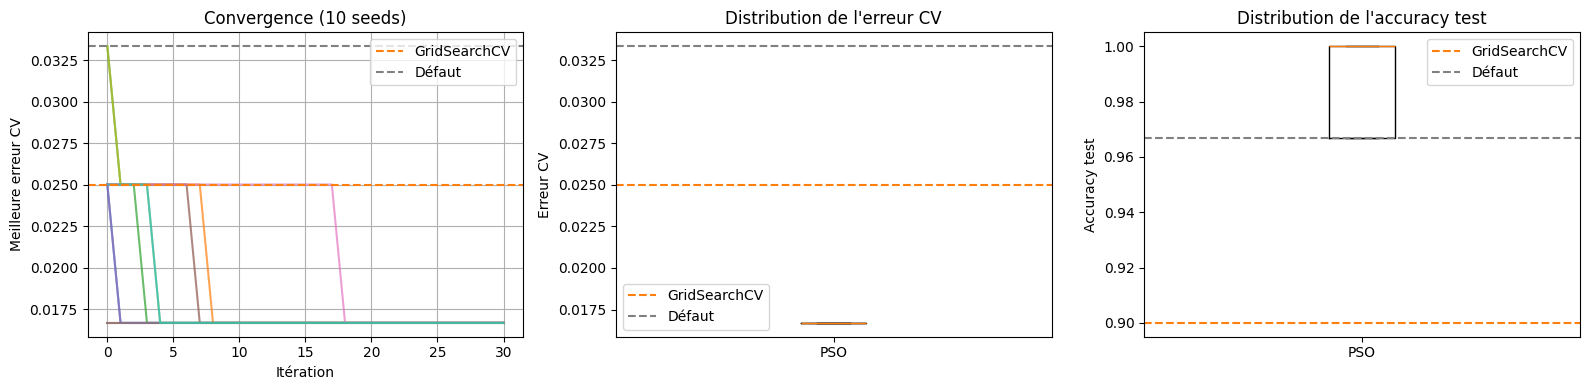

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) Courbes de convergence des 10 exécutions
for r in runs:
    axes[0].plot(r["history"], alpha=0.7)
axes[0].axhline(grid_err, color="tab:orange", linestyle="--", label="GridSearchCV")
axes[0].axhline(default_err, color="gray", linestyle="--", label="Défaut")
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("Meilleure erreur CV")
axes[0].set_title("Convergence (10 seeds)")
axes[0].legend()
axes[0].grid(True)

# (b) Distribution de l'erreur CV
axes[1].boxplot(df_runs["Erreur CV"])
axes[1].set_xticks([1], ["PSO"])
axes[1].axhline(grid_err, color="tab:orange", linestyle="--", label="GridSearchCV")
axes[1].axhline(default_err, color="gray", linestyle="--", label="Défaut")
axes[1].set_ylabel("Erreur CV")
axes[1].set_title("Distribution de l'erreur CV")
axes[1].legend()

# (c) Distribution de l'accuracy test
axes[2].boxplot(df_runs["Accuracy test"])
axes[2].set_xticks([1], ["PSO"])
axes[2].axhline(acc_grid, color="tab:orange", linestyle="--", label="GridSearchCV")
axes[2].axhline(acc_default, color="gray", linestyle="--", label="Défaut")
axes[2].set_ylabel("Accuracy test")
axes[2].set_title("Distribution de l'accuracy test")
axes[2].legend()

plt.tight_layout()
plt.savefig("resultats/fig7_repetitions.png", dpi=150)
plt.show()

Influence de l’inertie w
Objectif:
Étudier comment le paramètre w change le comportement du PSO. On compare trois valeurs :

lancer les expériences

In [32]:
w_values = [0.4, 0.7, 0.9]
seeds_w = [SEED + i for i in range(5)]      # 42 à 46
target = 1/60 + 1e-9                         # erreur CV de 2 erreurs sur 120 (0.0167)

res_w = {}
for w in w_values:
    hists, disps, finals, firsts, times = [], [], [], [], []
    for s in seeds_w:
        t0 = time.time()
        g, g_val, hist, pos_hist = pso(objective, bounds, n_particles=20, n_iter=30,
                                       w=w, c1=1.5, c2=1.5, seed=s, verbose=False)
        times.append(time.time() - t0)

        hist = np.array(hist)
        hists.append(hist)
        disps.append([np.std(p, axis=0).mean() for p in pos_hist])
        finals.append(g_val)
        firsts.append(np.argmax(hist <= target) if (hist <= target).any() else np.nan)

    res_w[w] = {"hists": np.array(hists), "disps": np.array(disps),
                "finals": finals, "firsts": firsts, "times": times}
    print(f"w = {w} terminé | erreurs finales : {np.round(finals, 4)} | "
          f"itération d'atteinte : {firsts}")

w = 0.4 terminé | erreurs finales : [0.0167 0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [np.int64(1), np.int64(3), np.int64(14), np.int64(0), np.int64(1)]
w = 0.7 terminé | erreurs finales : [0.0167 0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [np.int64(1), np.int64(8), np.int64(3), np.int64(0), np.int64(1)]
w = 0.9 terminé | erreurs finales : [0.0167 0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [np.int64(1), np.int64(2), np.int64(5), np.int64(0), np.int64(1)]


tableau récapitulatif

In [33]:
tab_w = pd.DataFrame({
    "w": w_values,
    "Erreur CV finale (moy)": [np.mean(res_w[w]["finals"]) for w in w_values],
    "Erreur CV finale (écart-type)": [np.std(res_w[w]["finals"], ddof=1) for w in w_values],
    "Runs ayant atteint 0.0167": [f"{np.sum(~np.isnan(res_w[w]['firsts']))}/5" for w in w_values],
    "Itération d'atteinte (moy)": [np.nanmean(res_w[w]["firsts"]) if not np.all(np.isnan(res_w[w]["firsts"])) else np.nan for w in w_values],
    "Dispersion finale (moy)": [res_w[w]["disps"][:, -1].mean() for w in w_values],
    "Temps moyen (s)": [np.mean(res_w[w]["times"]) for w in w_values],
}).round(4)

print(tab_w.to_string(index=False))
tab_w.to_csv("resultats/tableau_influence_w.csv", index=False)

  w  Erreur CV finale (moy)  Erreur CV finale (écart-type) Runs ayant atteint 0.0167  Itération d'atteinte (moy)  Dispersion finale (moy)  Temps moyen (s)
0.4                  0.0167                            0.0                       5/5                         3.8                   0.2506          25.1935
0.7                  0.0167                            0.0                       5/5                         2.6                   0.3860          23.0796
0.9                  0.0167                            0.0                       5/5                         1.8                   0.8845          19.6571


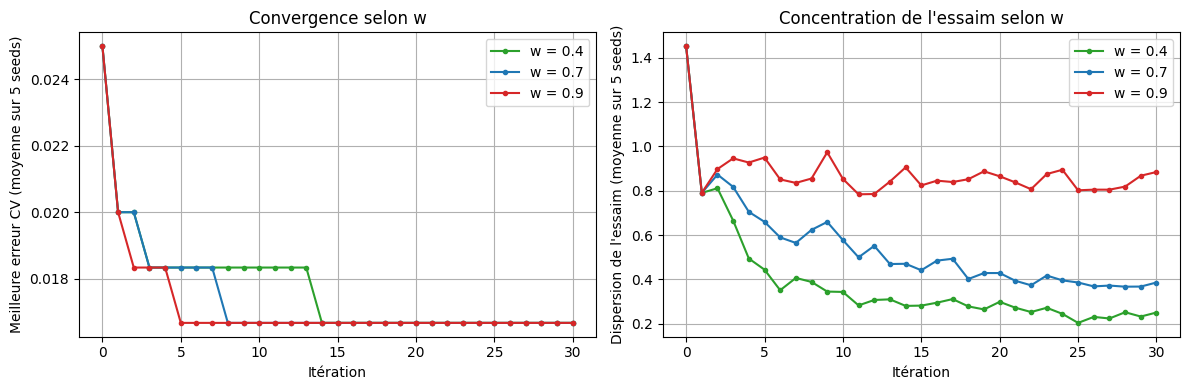

In [34]:
couleurs = {0.4: "tab:green", 0.7: "tab:blue", 0.9: "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (a) Convergence moyenne
for w in w_values:
    axes[0].plot(res_w[w]["hists"].mean(axis=0), label=f"w = {w}", color=couleurs[w], marker="o", markersize=3)
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("Meilleure erreur CV (moyenne sur 5 seeds)")
axes[0].set_title("Convergence selon w")
axes[0].legend()
axes[0].grid(True)

# (b) Dispersion moyenne de l'essaim
for w in w_values:
    axes[1].plot(res_w[w]["disps"].mean(axis=0), label=f"w = {w}", color=couleurs[w], marker="o", markersize=3)
axes[1].set_xlabel("Itération")
axes[1].set_ylabel("Dispersion de l'essaim (moyenne sur 5 seeds)")
axes[1].set_title("Concentration de l'essaim selon w")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("resultats/fig8_influence_w.png", dpi=150)
plt.show()

Influence du nombre de particules
Objectif:
Étudier comment la taille de l’essaim change le comportement du PSO. On compare :

10 particules : essaim petit (310 évaluations par run)
20 particules : valeur utilisée jusqu’ici (620 évaluations)
50 particules : essaim grand (1550 évaluations)

lancer les experiences

In [35]:
n_values = [10, 20, 50]
seeds_n = [SEED + i for i in range(5)]       # 42 à 46 (mêmes seeds qu'à l'étape 8)
target = 1/60 + 1e-9

res_n = {}
for n in n_values:
    if n == 20:
        # Réutilisation de l'étape 8 (w = 0.7, mêmes seeds, mêmes paramètres)
        r = res_w[0.7]
        res_n[n] = {"hists": r["hists"], "disps": r["disps"], "finals": r["finals"],
                    "firsts": r["firsts"], "times": r["times"]}
    else:
        hists, disps, finals, firsts, times = [], [], [], [], []
        for s in seeds_n:
            t0 = time.time()
            g, g_val, hist, pos_hist = pso(objective, bounds, n_particles=n, n_iter=30,
                                           w=0.7, c1=1.5, c2=1.5, seed=s, verbose=False)
            times.append(time.time() - t0)

            hist = np.array(hist)
            hists.append(hist)
            disps.append([np.std(p, axis=0).mean() for p in pos_hist])
            finals.append(g_val)
            firsts.append(int(np.argmax(hist <= target)) if (hist <= target).any() else np.nan)

        res_n[n] = {"hists": np.array(hists), "disps": np.array(disps),
                    "finals": finals, "firsts": firsts, "times": times}

    print(f"n = {n} prêt | erreurs finales : {np.round(res_n[n]['finals'], 4)} | "
          f"itération d'atteinte : {[None if np.isnan(f) else int(f) for f in res_n[n]['firsts']]}")

n = 10 prêt | erreurs finales : [0.025  0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [None, 7, 9, 0, 7]
n = 20 prêt | erreurs finales : [0.0167 0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [1, 8, 3, 0, 1]
n = 50 prêt | erreurs finales : [0.0167 0.0167 0.0167 0.0167 0.0167] | itération d'atteinte : [1, 1, 1, 0, 1]


tableau récapitulatif

In [37]:
def evals_pour_atteindre(n):
    f = np.array(res_n[n]["firsts"], dtype=float)
    return n * (f + 1)        # évaluations = n_particules × (itération + 1)

tab_n = pd.DataFrame({
    "Particules": n_values,
    "Évaluations totales": [n * 31 for n in n_values],
    "Erreur CV finale (moy)": [np.mean(res_n[n]["finals"]) for n in n_values],
    "Runs ayant atteint 0.0167": [f"{np.sum(~np.isnan(np.array(res_n[n]['firsts'], dtype=float)))}/5" for n in n_values],
    "Itération d'atteinte (moy)": [np.nanmean(np.array(res_n[n]["firsts"], dtype=float)) for n in n_values],
    "Évaluations pour atteindre (moy)": [np.nanmean(evals_pour_atteindre(n)) for n in n_values],
    "Dispersion finale (moy)": [res_n[n]["disps"][:, -1].mean() for n in n_values],
    "Temps moyen (s)": [np.mean(res_n[n]["times"]) for n in n_values],
}).round(4)

print(tab_n.to_string(index=False))
tab_n.to_csv("resultats/tableau_influence_n.csv", index=False)

print("\nDétail par seed (évaluations pour atteindre 0.0167) :")
for n in n_values:
    print(f"  n = {n:2d} :", evals_pour_atteindre(n))   # NaN = jamais atteint

 Particules  Évaluations totales  Erreur CV finale (moy) Runs ayant atteint 0.0167  Itération d'atteinte (moy)  Évaluations pour atteindre (moy)  Dispersion finale (moy)  Temps moyen (s)
         10                  310                  0.0183                       4/5                        5.75                              67.5                   0.2678          13.7690
         20                  620                  0.0167                       5/5                        2.60                              72.0                   0.3860          23.0796
         50                 1550                  0.0167                       5/5                        0.80                              90.0                   0.4296          49.6300

Détail par seed (évaluations pour atteindre 0.0167) :
  n = 10 : [ nan  80. 100.  10.  80.]
  n = 20 : [ 40. 180.  80.  20.  40.]
  n = 50 : [100. 100. 100.  50. 100.]


figures

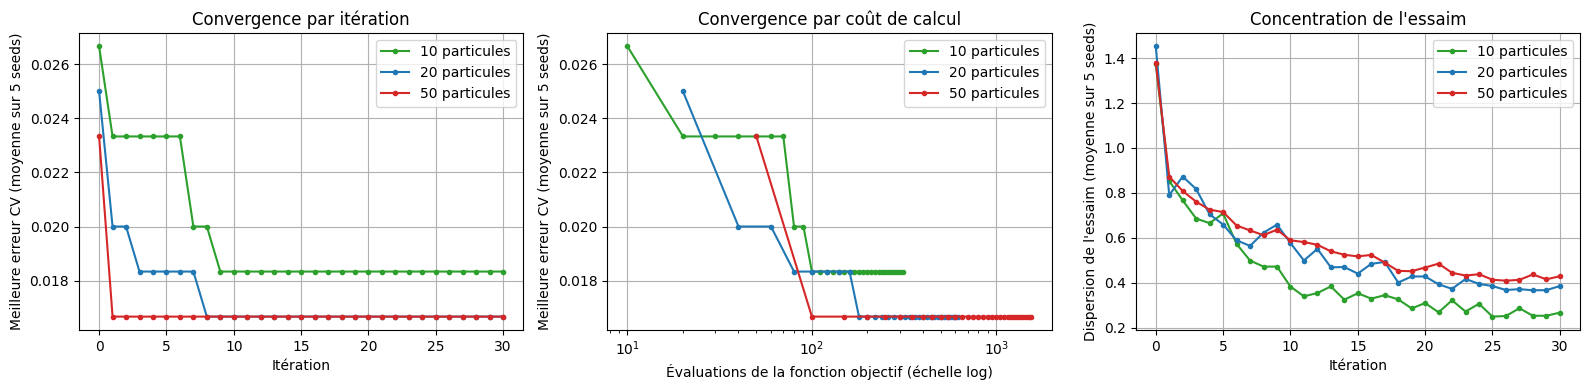

In [38]:
couleurs_n = {10: "tab:green", 20: "tab:blue", 50: "tab:red"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# (a) Convergence selon les itérations
for n in n_values:
    axes[0].plot(res_n[n]["hists"].mean(axis=0), label=f"{n} particules",
                 color=couleurs_n[n], marker="o", markersize=3)
axes[0].set_xlabel("Itération")
axes[0].set_ylabel("Meilleure erreur CV (moyenne sur 5 seeds)")
axes[0].set_title("Convergence par itération")
axes[0].legend()
axes[0].grid(True)

# (b) Convergence selon le nombre d'évaluations (comparaison du coût réel)
for n in n_values:
    evals_axis = n * (np.arange(31) + 1)
    axes[1].plot(evals_axis, res_n[n]["hists"].mean(axis=0), label=f"{n} particules",
                 color=couleurs_n[n], marker="o", markersize=3)
axes[1].set_xscale("log")
axes[1].set_xlabel("Évaluations de la fonction objectif (échelle log)")
axes[1].set_ylabel("Meilleure erreur CV (moyenne sur 5 seeds)")
axes[1].set_title("Convergence par coût de calcul")
axes[1].legend()
axes[1].grid(True)

# (c) Dispersion de l'essaim
for n in n_values:
    axes[2].plot(res_n[n]["disps"].mean(axis=0), label=f"{n} particules",
                 color=couleurs_n[n], marker="o", markersize=3)
axes[2].set_xlabel("Itération")
axes[2].set_ylabel("Dispersion de l'essaim (moyenne sur 5 seeds)")
axes[2].set_title("Concentration de l'essaim")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig("resultats/fig9_influence_particules.png", dpi=150)
plt.show()

Synthèse finale 

In [39]:
synthese = pd.DataFrame({
    "Méthode": ["Défaut", "GridSearchCV", "PSO (10 seeds)"],
    "Erreur CV": [default_err, grid_err, df_runs["Erreur CV"].mean()],
    "Accuracy test": [acc_default, acc_grid, df_runs["Accuracy test"].mean()],
    "Écart-type acc. test": [None, None, df_runs["Accuracy test"].std()],
    "Évaluations": [1, 625, 620],
}).round(4)

print(synthese.to_string(index=False))
synthese.to_csv("resultats/tableau_synthese.csv", index=False)

       Méthode  Erreur CV  Accuracy test  Écart-type acc. test  Évaluations
        Défaut     0.0333         0.9667                   NaN            1
  GridSearchCV     0.0250         0.9000                   NaN          625
PSO (10 seeds)     0.0167         0.9867                0.0172          620


In [40]:
for f in sorted(os.listdir("resultats")):
    print(f)

.ipynb_checkpoints
fig1_donnees_iris.png
fig2_paysage_objectif.png
fig3_convergence_pso.png
fig4_essaim.png
fig6_comparaison.png
fig7_repetitions.png
fig8_influence_w.png
fig9_influence_particules.png
tableau_comparaison.csv
tableau_influence_n.csv
tableau_influence_w.csv
tableau_repetitions.csv
tableau_synthese.csv


In [41]:
import sys, sklearn
print("Python :", sys.version.split()[0])
print("numpy :", np.__version__)
print("scikit-learn :", sklearn.__version__)
print("pandas :", pd.__version__)

Python : 3.12.0
numpy : 2.4.3
scikit-learn : 1.8.0
pandas : 3.0.1
